<a href="https://colab.research.google.com/github/seitoyokota/python/blob/main/11_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import matplotlib.pyplot as plt
import random
random.seed(50)

In [2]:
days = list(range(1,31))
print(days)

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]


In [3]:
solar_kwh = [round(random.uniform(25.0,65.0),1) for _ in days]
print(solar_kwh)

[44.9, 35.6, 50.5, 34.7, 43.9, 63.8, 28.4, 37.7, 52.1, 28.4, 31.1, 58.0, 64.2, 37.8, 32.6, 63.9, 38.2, 49.2, 49.3, 50.4, 61.6, 63.5, 52.7, 58.0, 56.8, 50.7, 42.2, 34.1, 35.6, 62.2]


In [4]:
demand_kwh = [
    round(random.uniform(45.0,70.0),1) if (day % 7 == 6 or day % 7 == 0)
    else round(random.uniform(20.0, 50.0), 1)
    for day in days
]
# for d in days:
#   if day % 7 == 6 or day % 7 == 0:
#     demand_kwh.append(round(random.uniform(45.0,70.0),1))
#   else:
#     demand_kwh.append(round(random.uniform(20.0,50.0),1))
print(demand_kwh)

[41.0, 23.2, 47.3, 28.1, 40.8, 56.5, 51.7, 26.3, 37.4, 32.4, 38.7, 40.9, 65.5, 66.3, 38.8, 49.0, 34.9, 46.6, 44.4, 65.4, 48.1, 37.1, 35.5, 22.8, 31.0, 35.5, 45.2, 45.2, 37.6, 32.3]


In [5]:
net_kwh = [round(s-d,1) for s,d in zip(solar_kwh,demand_kwh)]
print(net_kwh)

[3.9, 12.4, 3.2, 6.6, 3.1, 7.3, -23.3, 11.4, 14.7, -4.0, -7.6, 17.1, -1.3, -28.5, -6.2, 14.9, 3.3, 2.6, 4.9, -15.0, 13.5, 26.4, 17.2, 35.2, 25.8, 15.2, -3.0, -11.1, -2.0, 29.9]


In [6]:
bar_colors = ['seagreen' if n>=0 else 'crimson' for n in net_kwh]
print(bar_colors)

['seagreen', 'seagreen', 'seagreen', 'seagreen', 'seagreen', 'seagreen', 'crimson', 'seagreen', 'seagreen', 'crimson', 'crimson', 'seagreen', 'crimson', 'crimson', 'crimson', 'seagreen', 'seagreen', 'seagreen', 'seagreen', 'crimson', 'seagreen', 'seagreen', 'seagreen', 'seagreen', 'seagreen', 'seagreen', 'crimson', 'crimson', 'crimson', 'seagreen']


In [7]:
surplus_days = [day for day, n in zip(days,net_kwh) if n>10.0]
print(surplus_days)

[2, 8, 9, 12, 16, 21, 22, 23, 24, 25, 26, 30]


In [8]:
surplus_vals = [n for n in net_kwh if n>10.0]
print(surplus_vals)

[12.4, 11.4, 14.7, 17.1, 14.9, 13.5, 26.4, 17.2, 35.2, 25.8, 15.2, 29.9]


In [9]:
bubble_sizes = [v*6 for v in surplus_vals]
print(bubble_sizes)

[74.4, 68.4, 88.19999999999999, 102.60000000000001, 89.4, 81.0, 158.39999999999998, 103.19999999999999, 211.20000000000002, 154.8, 91.19999999999999, 179.39999999999998]


In [10]:
daily_cash = [
    round(n * 0.12, 2) if n>=0
    else round(n * 0.22, 2)
    for n in net_kwh
]
print(daily_cash)

[0.47, 1.49, 0.38, 0.79, 0.37, 0.88, -5.13, 1.37, 1.76, -0.88, -1.67, 2.05, -0.29, -6.27, -1.36, 1.79, 0.4, 0.31, 0.59, -3.3, 1.62, 3.17, 2.06, 4.22, 3.1, 1.82, -0.66, -2.44, -0.44, 3.59]


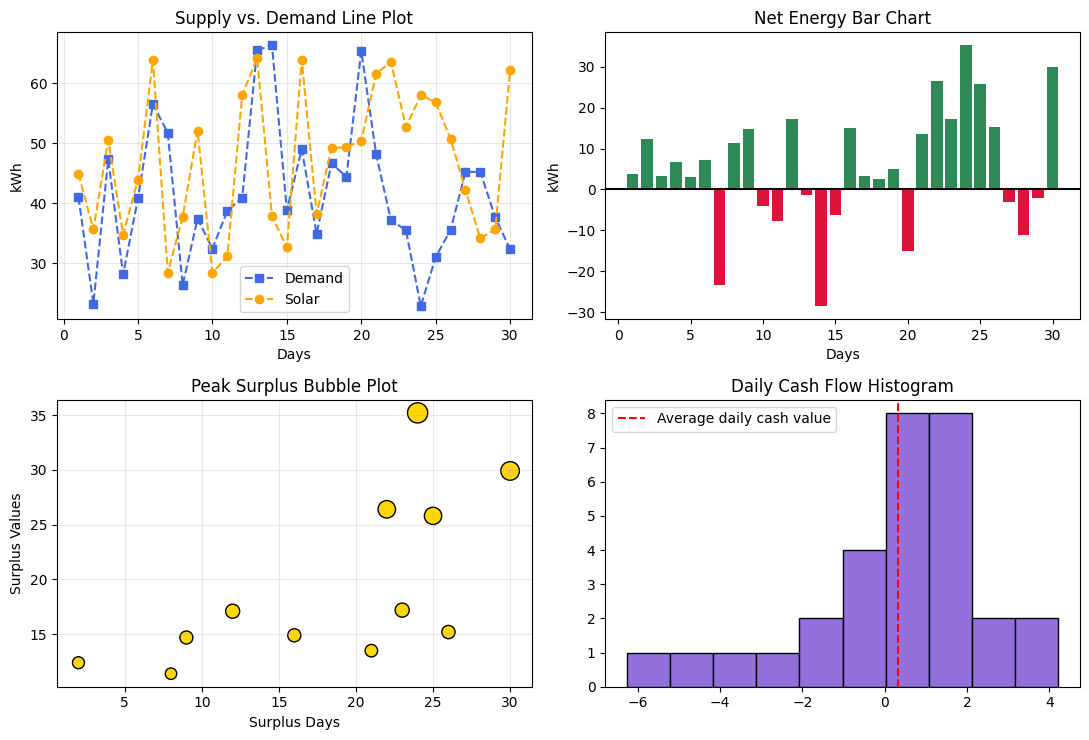

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))

tl = axes[0,0]
tl.plot(days,demand_kwh,color="royalblue",linestyle="--",marker="s", label="Demand")
tl.plot(days,solar_kwh,color="orange",linestyle="--",marker="o", label="Solar")
tl.legend()
tl.set_title("Supply vs. Demand Line Plot")
tl.set_xlabel("Days")
tl.set_ylabel("kWh")
tl.grid(True, alpha=0.3)

tr = axes[0,1]
tr.bar(days,net_kwh,color=bar_colors)
tr.axhline(y=0,color="black")
tr.set_title("Net Energy Bar Chart")
tr.set_xlabel("Days")
tr.set_ylabel("kWh")

bl = axes[1,0]
bl.scatter(surplus_days,surplus_vals,s=bubble_sizes,color="gold",edgecolor="black")
bl.set_title("Peak Surplus Bubble Plot")
bl.set_xlabel("Surplus Days")
bl.set_ylabel("Surplus Values")
bl.grid(True, alpha=0.3)


br = axes[1,1]
br.hist(daily_cash,bins=10,color="mediumpurple",edgecolor="black")
br.axvline(x=sum(daily_cash) / len(daily_cash),color="red",linestyle="--", label="Average daily cash value")
br.legend()
br.set_title("Daily Cash Flow Histogram")

plt.tight_layout()
plt.show()